In [1]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import DBSCAN
import re
from sklearn.metrics import silhouette_score
from sklearn.model_selection import ParameterGrid

In [2]:
data = pd.read_csv('/Users/nicolasbour/Desktop/Projets_IA/Projets_certif/bloc_03_Machine_Learning/03_the_north_face/sample-data.csv')

In [3]:
data.head()

,id,description
0,1,Active classic boxers - There's a reason why o...
1,2,Active sport boxer briefs - Skinning up Glory ...
2,3,Active sport briefs - These superbreathable no...
3,4,"Alpine guide pants - Skin in, climb ice, switc..."
4,5,"Alpine wind jkt - On high ridges, steep ice an..."


In [4]:
data["raw"] = data["description"].reset_index(drop=True)

In [5]:
data[["label", "description"]] = data["description"].str.split(
    r"\s+-\s+", n=1, expand=True
).reset_index(drop=True)

In [6]:
data.head()

,id,description,raw,label
0,1,There's a reason why our boxers are a cult fav...,Active classic boxers - There's a reason why o...,Active classic boxers
1,2,Skinning up Glory requires enough movement wit...,Active sport boxer briefs - Skinning up Glory ...,Active sport boxer briefs
2,3,These superbreathable no-fly briefs are the mi...,Active sport briefs - These superbreathable no...,Active sport briefs
3,4,"Skin in, climb ice, switch to rock, traverse a...","Alpine guide pants - Skin in, climb ice, switc...",Alpine guide pants
4,5,"On high ridges, steep ice and anything alpine,...","Alpine wind jkt - On high ridges, steep ice an...",Alpine wind jkt


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           500 non-null    int64 
 1   description  500 non-null    object
 2   raw          500 non-null    object
 3   label        500 non-null    object
dtypes: int64(1), object(3)
memory usage: 15.8+ KB


In [8]:
data.isnull().sum()

id             0
description    0
raw            0
label          0
dtype: int64

In [9]:
data.nunique()

id             500
description    492
raw            500
label          417
dtype: int64

In [10]:
# Lignes dont le label apparaît plusieurs fois
doublons_label = data[data.duplicated(subset="label", keep=False)]
display(doublons_label.sort_values("label"))

# Lignes dont la description apparaît plusieurs fois
doublons_description = data[data.duplicated(subset="description", keep=False)]
display(doublons_description.sort_values("description"))

,id,description,raw,label
492,493,Patagonia's timeless '73 Logo T-Shirt pays hom...,'73 logo t-shirt - Patagonia's timeless '73 Lo...,'73 logo t-shirt
57,58,Soft-wearing ringspun organic cotton; Screen-p...,'73 logo t-shirt - Soft-wearing ringspun organ...,'73 logo t-shirt
494,495,"These featherweight, quick-wicking briefs keep...","Active briefs - These featherweight, quick-wic...",Active briefs
299,300,Whether you're beating the heat in Bali or ski...,Active briefs - Whether you're beating the hea...,Active briefs
497,498,No need to use that morning Times as an umbrel...,All-time shell - No need to use that morning T...,All-time shell
...,...,...,...,...
425,426,Mom and Dad may remember when hats like this k...,Trucker hat - Mom and Dad may remember when ha...,Trucker hat
152,153,"long - Blackberries, barbwire, basalt...the fa...","Watermaster waders - long - Blackberries, barb...",Watermaster waders
153,154,"short - Blackberries, barbwire, basalt...the f...","Watermaster waders - short - Blackberries, bar...",Watermaster waders
354,355,"king - Blackberries, barbwire, basalt...the fa...","Watermaster waders - king - Blackberries, barb...",Watermaster waders


,id,description,raw,label
243,244,"Our fixed triangle bikini top, the Kupala, has...",Print kupala top - Our fixed triangle bikini t...,Print kupala top
252,253,"Our fixed triangle bikini top, the Kupala, has...",Solid kupala top - Our fixed triangle bikini t...,Solid kupala top
57,58,Soft-wearing ringspun organic cotton; Screen-p...,'73 logo t-shirt - Soft-wearing ringspun organ...,'73 logo t-shirt
62,63,Soft-wearing ringspun organic cotton; Screen-p...,Flying fish t-shirt - Soft-wearing ringspun or...,Flying fish t-shirt
63,64,Soft-wearing ringspun organic cotton; Screen-p...,Gpiw classic t-shirt - Soft-wearing ringspun o...,Gpiw classic t-shirt
64,65,Soft-wearing ringspun organic cotton; Screen-p...,Live simply guitar t-shirt - Soft-wearing ring...,Live simply guitar t-shirt
431,432,Soft-wearing ringspun organic cotton; Screen-p...,Girl's live simply deer t-shirt - Soft-wearing...,Girl's live simply deer t-shirt
432,433,Soft-wearing ringspun organic cotton; Screen-p...,Girl's live simply seal t-shirt - Soft-wearing...,Girl's live simply seal t-shirt
254,255,Stay-put Sunamees fit straight across the hips...,Solid sunamee btm - Stay-put Sunamees fit stra...,Solid sunamee btm
261,262,Stay-put Sunamees fit straight across the hips...,Print sunamee btm - Stay-put Sunamees fit stra...,Print sunamee btm


Les doublons montrent que certains produits ont le même label ou la même description. Cela ne semble pas indiquer une erreur mais plutôt que certains produits montrent des variations qui impliquent le même label ou la même description. Il n'y a aucun doublon exact, donc nous ne supprimerons pas de lignes.

In [23]:
def text_cleaning(text): 
    """Mettre en minuscules,
    Remplacer la ponctuation et les caractères spéciaux par des espaces, Supprimer les espaces en trop"""

    text = text.lower()
    text = re.sub(r"[\W_]+", " ", text)
    return text.strip()

data["clean_text"] = data["raw"].fillna("").apply(text_cleaning)

In [24]:
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_df=0.95,
    min_df=2
)

# Remplace les valeurs manquantes par une chaîne vide
matrice_tfidf = vectorizer.fit_transform(data["clean_text"].fillna(""))

print("Dimensions :", matrice_tfidf.shape)
print("Exemples de mots :", vectorizer.get_feature_names_out()[:20])

Dimensions : (500, 2627)
Exemples de mots : ['000' '10' '100' '103' '108' '109' '1096' '11' '112' '115' '118' '1188'
 '12' '1200' '121' '124' '126' '129' '13' '130']


In [25]:
pd.DataFrame(
    matrice_tfidf[:5].toarray(),
    columns=vectorizer.get_feature_names_out()
)

,000,10,100,103,108,109,1096,11,112,115,...,yoga,yoke,yosemite,zip,zipper,zippered,zippers,zipping,zips,zones
0,0.0,0.000000,0.082420,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
1,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
2,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
3,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.239127,0.073411,0.0,0.0,0.0
4,0.0,0.047864,0.047224,0.0,0.0,0.0,0.0,0.060493,0.0,0.0,...,0.0,0.0,0.0,0.0,0.089478,0.035540,0.054554,0.0,0.0,0.0


In [26]:
dbscan = DBSCAN(
    eps=0.5,
    min_samples=10,
    metric="cosine"
)

In [27]:
data["cluster"] = dbscan.fit_predict(matrice_tfidf)

display(data["cluster"].value_counts().sort_index())

cluster
-1    420
 0     10
 1     55
 2     15
Name: count, dtype: int64

In [28]:
display(data.sort_values("cluster"))

,id,description,raw,label,clean_text,cluster
0,1,There's a reason why our boxers are a cult fav...,Active classic boxers - There's a reason why o...,Active classic boxers,active classic boxers there s a reason why our...,-1
325,326,The unofficial short for those who wander arou...,Thrift shorts - The unofficial short for those...,Thrift shorts,thrift shorts the unofficial short for those w...,-1
324,325,Wavefarers won't bunch up during a long paddle...,Wavefarer board shorts - Wavefarers won't bunc...,Wavefarer board shorts,wavefarer board shorts wavefarers won t bunch ...,-1
323,324,Soft and stretchy Vitaliti pants make the trip...,Vitalti pants - Soft and stretchy Vitaliti pan...,Vitalti pants,vitalti pants soft and stretchy vitaliti pants...,-1
322,323,The stretch and refined drape of Vitaliti fabr...,Vitaliti vee - The stretch and refined drape o...,Vitaliti vee,vitaliti vee the stretch and refined drape of ...,-1
...,...,...,...,...,...,...
86,87,"In a day packed with decisions, this one's eas...",Merino 1 crew - In a day packed with decisions...,Merino 1 crew,merino 1 crew in a day packed with decisions t...,2
268,269,Our most versatile merino baselayer blends int...,Merino 2 t-shirt - Our most versatile merino b...,Merino 2 t-shirt,merino 2 t shirt our most versatile merino bas...,2
405,406,"A stop-and-go pace, like that of alpine climbi...","Merino 2 bottoms - A stop-and-go pace, like th...",Merino 2 bottoms,merino 2 bottoms a stop and go pace like that ...,2
201,202,Be moved by the people and culture of a new pl...,Merino 2 crew - Be moved by the people and cul...,Merino 2 crew,merino 2 crew be moved by the people and cultu...,2


In [29]:
print(f"Nombre de clusters : {len(set(data['cluster'])) - 1}")  # On soustrait 1 pour exclure le bruit (-1)

Nombre de clusters : 3


Le cluster -1 est le cluster considéré comme du bruit par l'algorithme Dbscan. Nous allons tenter de réduire le nombre de produits dans ce cluster en ajustant les paramètres de l'algorithme.

In [30]:
parametres = {
    "eps": [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    "min_samples": [2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15]
}

resultats = []

for params in ParameterGrid(parametres):
    clusters = DBSCAN(**params, metric="cosine").fit_predict(matrice_tfidf)
    sans_bruit = clusters != -1
    try : 
        score = silhouette_score(
            matrice_tfidf[sans_bruit],
            clusters[sans_bruit],
            metric="cosine"
        )
    except ValueError:
        score = np.nan

    resultats.append({
        **params,
        "silhouette": score,
        "%_bruit": (1 - sans_bruit.mean()) * 100,
        "nb_clusters": len(set(clusters)) - (1 if -1 in clusters else 0)
    })

resultats = pd.DataFrame(resultats)
display(resultats.sort_values("nb_clusters", ascending=False))

,eps,min_samples,silhouette,%_bruit,nb_clusters
0,0.4,2,0.603493,34.4,97
11,0.5,2,0.495682,24.0,96
22,0.6,2,0.334396,10.0,80
23,0.6,3,0.331665,24.4,44
12,0.5,3,0.480506,47.2,38
...,...,...,...,...,...
55,0.9,2,NaN,0.0,1
53,0.8,12,NaN,5.4,1
52,0.8,10,NaN,4.6,1
51,0.8,9,NaN,4.2,1


In [31]:
candidats = resultats[(resultats["nb_clusters"] <= 20) & (resultats["nb_clusters"] >= 10) & resultats["silhouette"].notna()]

In [32]:
display(candidats)

,eps,min_samples,silhouette,%_bruit,nb_clusters
2,0.4,4,0.566217,68.0,20
3,0.4,5,0.554212,74.6,12
14,0.5,5,0.484196,63.8,17
15,0.5,6,0.478590,70.2,11
26,0.6,6,0.379320,53.4,16
27,0.6,7,0.391923,59.4,12
28,0.6,8,0.400625,63.6,10
34,0.7,3,0.144669,4.8,18
35,0.7,4,0.154419,7.2,17
36,0.7,5,0.162720,11.8,12


In [33]:
if candidats.empty:
    print("Aucun modèle valide avec au maximum 20 clusters.")
else:
    meilleur = candidats.sort_values("silhouette", ascending=False).iloc[0]
    display(meilleur)

eps             0.400000
min_samples     4.000000
silhouette      0.566217
%_bruit        68.000000
nb_clusters    20.000000
Name: 2, dtype: float64

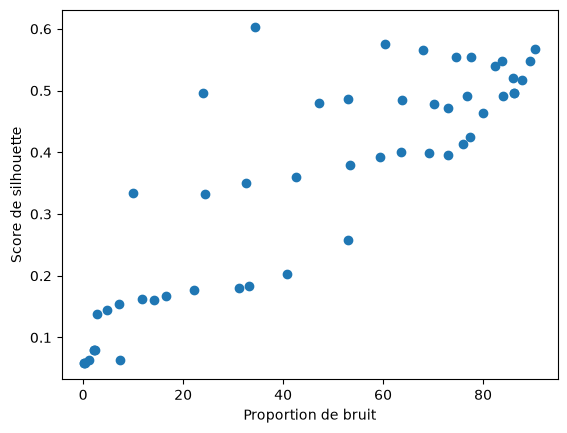

In [34]:
import matplotlib.pyplot as plt

plt.scatter(resultats["%_bruit"], resultats["silhouette"])
plt.xlabel("Proportion de bruit")
plt.ylabel("Score de silhouette")
plt.show()

Ce modele montre un score de silhouette difficile à choisir puisque dans les clusters selctionnés, le score de silhouette est très faible. Nous allons travailler sur les données pour améliorer le score de silhouette.